<a href="https://colab.research.google.com/github/indicadorel-ui/FundamentosDeSimulacionyModelacionProbabilistica/blob/main/T1_%7C_Fundamentos_de_Simulaci%C3%B3n_y_Modelaci%C3%B3n_Probabil%C3%ADstica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea 1. Fundamentos de Simulación y Modelación Probabilística

**Universidad Juárez del Estado de Durango**  
**Facultad de Ciencias Exactas**  
**Maestría en Estadística Aplicada**  
**Unidad de Aprendizaje:** Simulación Estocástica  
**Docente:** Dr. Gerónimo Quiñónez-Barraza  
**Estudiante:** Jesús Emmanuel Vázquez Macías  
**Fecha:** 31 de octubre de 2026

## Objetivo

Comprender las diferencias entre modelos determinísticos y estocásticos mediante una simulación computacional reproducible; además, generar números pseudoaleatorios y variables aleatorias de distribuciones uniforme, normal, exponencial y Poisson, describiendo sus propiedades mediante estadísticos y gráficos.

**Herramientas:** Python, NumPy, pandas, Matplotlib y Google Colab.  
**Semilla aleatoria:** 42.

## Preparación del entorno

Se importan las bibliotecas necesarias. La semilla se establecerá explícitamente en cada actividad para asegurar que los resultados puedan reproducirse al ejecutar el notebook de principio a fin.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Estilo de gráficos legible y reproducible
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10
})

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)

NumPy: 2.1.3
pandas: 2.2.3


# Actividad 1. Comparación de modelos determinísticos y estocásticos

## Planteamiento

Se modela el número de clientes de un servicio durante 30 días. Ambos modelos parten de **100 clientes** y usan una tasa media diaria de crecimiento del **3 %**.

- **Modelo determinístico:** el número de clientes crece exactamente 3 % cada día. No contiene aleatoriedad.
- **Modelo estocástico:** el crecimiento diario esperado es 3 %, pero se incorpora una perturbación aleatoria normal con media 0 y desviación estándar de 2 puntos porcentuales. Para evitar tasas negativas o valores extremos poco plausibles, la tasa diaria simulada se limita al intervalo de −5 % a 10 %.

La perturbación representa variaciones inesperadas de la demanda. Se fija la semilla en 42 para reproducir la trayectoria estocástica.

In [8]:
# Parámetros compartidos por ambos modelos
clientes_iniciales = 100
tasa_media = 0.03
dias = 30
semilla = 42

tiempo = np.arange(dias + 1)

# Modelo determinístico
clientes_deterministico = np.empty(dias + 1, dtype=float)
clientes_deterministico[0] = clientes_iniciales

for t in range(1, dias + 1):
    clientes_deterministico[t] = clientes_deterministico[t - 1] * (1 + tasa_media)

# Modelo estocástico: misma condición inicial y misma tasa media
rng = np.random.default_rng(semilla)
perturbaciones = rng.normal(loc=0, scale=0.02, size=dias)
tasas_diarias = np.clip(tasa_media + perturbaciones, -0.05, 0.10)

clientes_estocastico = np.empty(dias + 1, dtype=float)
clientes_estocastico[0] = clientes_iniciales

for t in range(1, dias + 1):
    clientes_estocastico[t] = clientes_estocastico[t - 1] * (1 + tasas_diarias[t - 1])

comparacion = pd.DataFrame({
    "Día": tiempo,
    "Modelo determinístico": clientes_deterministico,
    "Modelo estocástico": clientes_estocastico
})

display(comparacion.head(8).round(2))
print(f"Clientes al día {dias} — determinístico: {clientes_deterministico[-1]:.2f}")
print(f"Clientes al día {dias} — estocástico: {clientes_estocastico[-1]:.2f}")

,Día,Modelo determinístico,Modelo estocástico
0,0,100.00,100.00
1,1,103.00,103.61
2,2,106.09,104.56
3,3,109.27,109.27
4,4,112.55,114.60
5,5,115.93,113.57
6,6,119.41,114.02
7,7,122.99,117.73


Clientes al día 30 — determinístico: 242.73
Clientes al día 30 — estocástico: 244.30


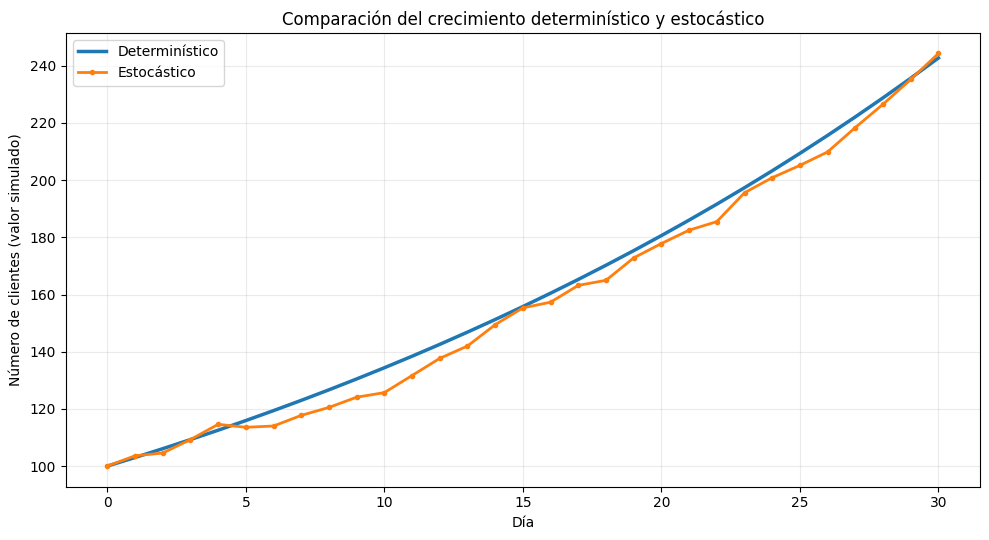

In [9]:
plt.figure(figsize=(10, 5.5))
plt.plot(tiempo, clientes_deterministico, linewidth=2.5, label="Determinístico")
plt.plot(tiempo, clientes_estocastico, linewidth=2, marker="o", markersize=3,
         label="Estocástico")
plt.xlabel("Día")
plt.ylabel("Número de clientes (valor simulado)")
plt.title("Comparación del crecimiento determinístico y estocástico")
plt.legend()
plt.tight_layout()
plt.show()

## Interpretación de la Actividad 1

El modelo determinístico produce una trayectoria única: con 100 clientes iniciales y crecimiento fijo de 3 % diario, el resultado queda completamente definido por los parámetros. El modelo estocástico parte de la misma condición inicial y conserva una tasa media de crecimiento de 3 %, pero añade fluctuaciones diarias que representan cambios inesperados en la demanda. Por ello, su trayectoria puede situarse por encima o por debajo de la determinística y el resultado final no coincide necesariamente con ella. La semilla 42 permite reproducir esta realización, aunque otra semilla podría generar una trayectoria distinta. Incorporar incertidumbre es importante cuando los fenómenos reales están sujetos a variaciones; permite estudiar escenarios posibles y evita interpretar una proyección puntual como si fuera una predicción segura. Esta simulación es ilustrativa y no constituye un pronóstico calibrado con datos reales.

# Actividad 2. Generación de números y variables aleatorias

Se generarán 1,000 valores de cada distribución solicitada. Se utiliza un generador pseudoaleatorio de NumPy con semilla 42. Los histogramas muestran la forma de las distribuciones continuas; para Poisson, que es discreta, se utiliza un gráfico de frecuencias. Se calcularán media, varianza muestral, desviación estándar muestral, mínimo y máximo. La varianza y desviación estándar se calculan con `ddof=1`, es decir, con la corrección muestral.

In [10]:
# Semilla reproducible para esta actividad
rng = np.random.default_rng(42)
n = 1000

datos = {
    "Uniforme U(0,1)": rng.uniform(0, 1, n),
    "Normal N(0,1)": rng.normal(0, 1, n),
    "Exponencial Exp(lambda=1)": rng.exponential(scale=1, size=n),
    "Poisson(lambda=5)": rng.poisson(lam=5, size=n)
}

def resumen_estadistico(valores):
    return {
        "Media": np.mean(valores),
        "Varianza muestral": np.var(valores, ddof=1),
        "Desviación estándar muestral": np.std(valores, ddof=1),
        "Mínimo": np.min(valores),
        "Máximo": np.max(valores)
    }

tabla_estadisticos = pd.DataFrame({
    nombre: resumen_estadistico(valores)
    for nombre, valores in datos.items()
}).T

display(tabla_estadisticos.round(4))

,Media,Varianza muestral,Desviación estándar muestral,Mínimo,Máximo
"Uniforme U(0,1)",0.4972,0.0850,0.2916,0.0012,0.9991
"Normal N(0,1)",-0.0779,1.0292,1.0145,-3.0476,2.9142
Exponencial Exp(lambda=1),0.9862,0.9659,0.9828,0.0002,9.5181
Poisson(lambda=5),4.9140,5.2639,2.2943,0.0000,14.0000


## Gráficos de las distribuciones simuladas

Cada panel representa una de las cuatro muestras. En la distribución uniforme, los valores deberían repartirse aproximadamente de manera homogénea entre 0 y 1. La normal debe mostrar una forma aproximadamente simétrica y acampanada. La exponencial es asimétrica hacia la derecha y solo toma valores no negativos. La distribución de Poisson es discreta, por lo que se representa mediante frecuencias enteras.

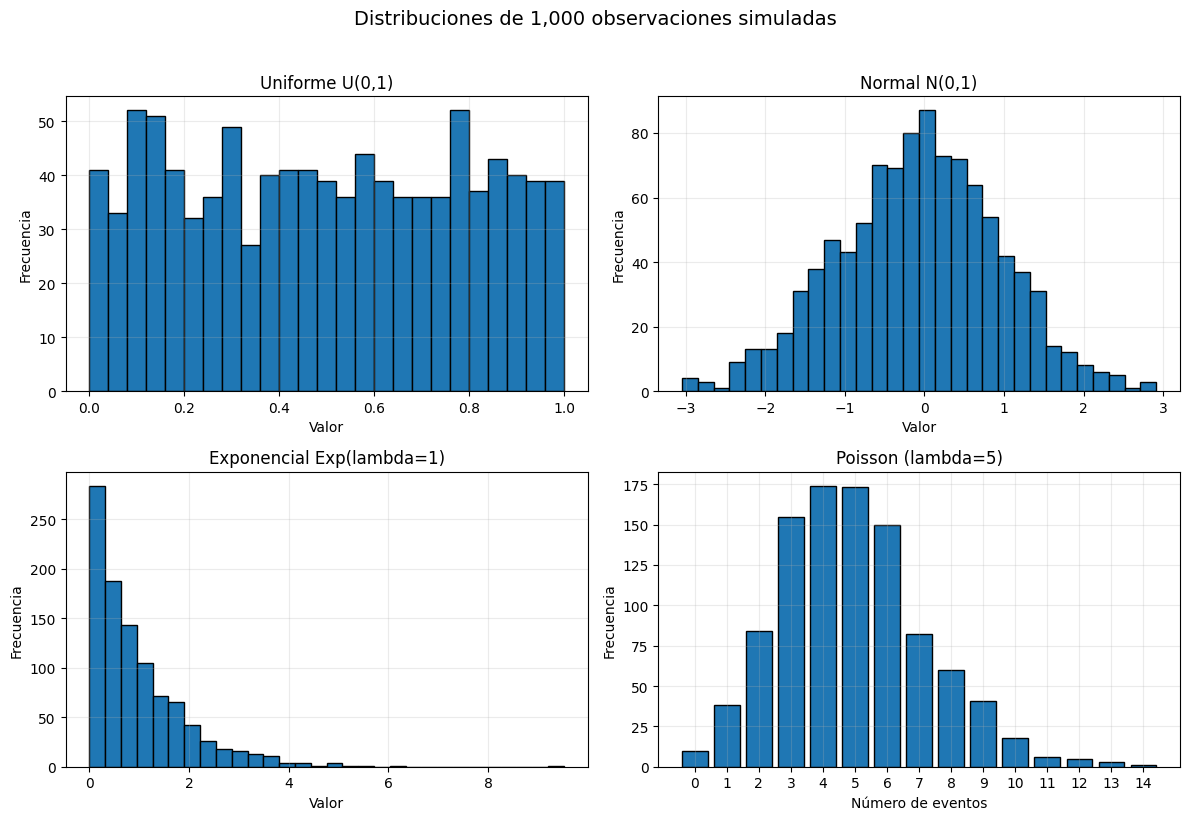

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Uniforme
axes[0, 0].hist(datos["Uniforme U(0,1)"], bins=25, edgecolor="black")
axes[0, 0].set_title("Uniforme U(0,1)")
axes[0, 0].set_xlabel("Valor")
axes[0, 0].set_ylabel("Frecuencia")

# Normal
axes[0, 1].hist(datos["Normal N(0,1)"], bins=30, edgecolor="black")
axes[0, 1].set_title("Normal N(0,1)")
axes[0, 1].set_xlabel("Valor")
axes[0, 1].set_ylabel("Frecuencia")

# Exponencial
axes[1, 0].hist(datos["Exponencial Exp(lambda=1)"], bins=30, edgecolor="black")
axes[1, 0].set_title("Exponencial Exp(lambda=1)")
axes[1, 0].set_xlabel("Valor")
axes[1, 0].set_ylabel("Frecuencia")

# Poisson: barras centradas en los valores enteros
valores_poisson, frecuencias_poisson = np.unique(datos["Poisson(lambda=5)"], return_counts=True)
axes[1, 1].bar(valores_poisson, frecuencias_poisson, edgecolor="black", width=0.8)
axes[1, 1].set_title("Poisson (lambda=5)")
axes[1, 1].set_xlabel("Número de eventos")
axes[1, 1].set_ylabel("Frecuencia")
axes[1, 1].set_xticks(np.arange(valores_poisson.min(), valores_poisson.max() + 1))

plt.suptitle("Distribuciones de 1,000 observaciones simuladas", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

## Comparación con los valores teóricos

Para una variable uniforme \(U(0,1)\), la media teórica es 0.5 y la varianza es \(1/12\). Para la normal estándar, la media es 0 y la varianza 1. Para la exponencial con tasa \(\lambda=1\), la media y la varianza son 1. Para Poisson con \(\lambda=5\), tanto la media como la varianza son 5. Las estadísticas de una muestra no tienen que coincidir exactamente con esos valores: presentan fluctuaciones aleatorias y suelen aproximarse a los valores teóricos al aumentar el tamaño de la muestra.

In [12]:
valores_teoricos = pd.DataFrame({
    "Media teórica": [0.5, 0.0, 1.0, 5.0],
    "Varianza teórica": [1/12, 1.0, 1.0, 5.0]
}, index=list(datos.keys()))

comparacion_teorica = valores_teoricos.join(
    tabla_estadisticos[["Media", "Varianza muestral"]]
)
comparacion_teorica["Diferencia media"] = (
    comparacion_teorica["Media"] - comparacion_teorica["Media teórica"]
)
comparacion_teorica["Diferencia varianza"] = (
    comparacion_teorica["Varianza muestral"] - comparacion_teorica["Varianza teórica"]
)

display(comparacion_teorica.round(4))

,Media teórica,Varianza teórica,Media,Varianza muestral,Diferencia media,Diferencia varianza
"Uniforme U(0,1)",0.5,0.0833,0.4972,0.0850,-0.0028,0.0017
"Normal N(0,1)",0.0,1.0000,-0.0779,1.0292,-0.0779,0.0292
Exponencial Exp(lambda=1),1.0,1.0000,0.9862,0.9659,-0.0138,-0.0341
Poisson(lambda=5),5.0,5.0000,4.9140,5.2639,-0.0860,0.2639


## Interpretación de la Actividad 2

Las cuatro muestras presentan comportamientos coherentes con sus distribuciones teóricas. La uniforme distribuye los valores aproximadamente por igual entre 0 y 1, con media cercana a 0.5. La normal estándar se concentra alrededor de cero y presenta simetría, con media y varianza esperadas de 0 y 1. La exponencial solo genera valores no negativos y muestra asimetría positiva: abundan valores pequeños y aparecen algunos valores grandes; su media y varianza teóricas son 1. La distribución de Poisson es discreta y modela conteos; con parámetro 5, su media y varianza teóricas son ambas iguales a 5. Las estadísticas simuladas pueden diferir de los valores teóricos debido a la variabilidad muestral. Con 1,000 observaciones, las estimaciones suelen ser razonablemente cercanas, pero no idénticas. La semilla 42 hace reproducible la muestra generada.

# Conclusión general

La actividad permitió distinguir entre una simulación determinística, que entrega una trayectoria fija para parámetros dados, y una estocástica, que representa variaciones aleatorias y posibles escenarios. Asimismo, se generaron de manera reproducible muestras de cuatro distribuciones probabilísticas y se analizaron sus estadísticos descriptivos y formas gráficas. La comparación entre estimaciones muestrales y valores teóricos muestra cómo la variabilidad aleatoria afecta los resultados y por qué es importante considerar tanto el modelo probabilístico como el tamaño de muestra al interpretar una simulación.